# Prefilter — DA, $\lambda$=0.003 (primary)

Primary model of this notebook:

    trained_models/prefilter/da_prefilter_numu_261108_1943_Qclip_hardlabels_FocalLoss_muOnlyDA_k10_refresh5_probe/best_da_model.pth

The companion notebook, `control__analysis.ipynb`, makes the other model of the pair primary.
Every figure below draws **this** model solid and the other dashed, so the
comparison is on each plot rather than only across notebooks.

## The pair

Both runs are the DA-repair prefilter retrain on hard labels. They share the
`hard_nu_labels` source dataset, a muatm-only adversarial source, `k_steps=10`,
a discriminator refresh every 5 epochs, LayerNorm + instance noise in the
discriminator, the same invariance probe, seed 42, architecture and `exp.h5`
target. They differ **only** in the adversarial strength:

| run | `lambda_scheduler` |
|---|---|
| DA | `delayed_constant`, $\lambda=0.003$ from epoch 2 |
| control | `constant`, $\lambda=0.0$ |

So this is domain adaptation against a matched no-DANN control. The control
still trains the discriminator (`k_steps`, refresh) and still runs the probe;
the encoder simply receives no domain gradient.

## Predictions and cuts

MC is **out-of-training**: the predictions were scored on the canonical
held-out part lists with `predict_mc.py --exclude-trained-parts`, which drops
all 952 parts the training dataset was built from (432 muatm + 187 nuatm + 333
nue2). The sample was capped at 10M muatm, 3M nuatm and all 1.29M nue2 per
model; `exp_full` is complete (133,294,745 events). The exact commands are in
`run_predictions.sh`.

Figures 1–3 use **h8s3 on MC truth** (`n_gt_sig_hits >= 8 AND
n_gt_sig_strings >= 3`). Figure 4 uses **h8s3 by the sig-noise model**
(`n_sn_hits >= 8 AND n_sn_strings >= 3` at threshold 0.8) for both `exp_full`
and muatm. Both count pairs are stored per event in the prediction databases,
copied verbatim from the probabilities file; the prefilter itself still scores
**all** raw hits, and these counts are analysis metadata, never a selection.

## Everything is read through `inference.reader`

Zenith angle, primary energy and the MC event weight are not in the catalog;
they live in `prime_prty` in `baikal_mc_merged.h5` and the reader returns them
beside each event as `prime_theta_deg`, `prime_energy_gev` and
`prime_event_weight`. `exp_full` is never materialised: its 133M scored events
are read only as aggregates through `Reader.histogram`.

## Caveats carried onto the figures

* **Weights.** `EventWeight` is applied within a class only, so the metrics stay
  defined whether or not it is comparable *between* muatm, nuatm and nue2 — that
  comparability is `assumed`, not checked. Weighted and unweighted panels are
  drawn side by side.
* **`nue2` is astrophysical nu_mu with an E^-2 spectrum**, not electron neutrinos.
* **No live-time normalisation** exists for this MC, so figure 4 is a shape
  ratio and its absolute level is not a rate.
* **The MC classes occupy disjoint zenith hemispheres** — muatm 94.2–179.9 deg,
  both neutrino classes 0.11–90.00 deg — so the separation shown is easier than
  a real sample would offer. Logged in `doc/claims_log.md`.
* **Two exp_full runs** are dropped by `reader.NOT_EXCLUDED`; the flag
  `EXCLUDE_BAD_EXP_RUNS` below turns this off.
* **The MC sample is reduced** (10M/3M/1.29M), unlike the canonical 127M
  prediction set; the figures are statistically limited accordingly.


In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))
import numpy as np
import pandas as pd
import report_lib as R

PRIMARY = "da"

# reader.NOT_EXCLUDED drops the two exp_full runs where channels 222/224/225/227
# emit up to 3169.8 p.e. against a median hit of 0.97 (inference/reader/spec.py).
# Set to False to keep them; the counts either way are printed below.
EXCLUDE_BAD_EXP_RUNS = True

print("primary:", R.MODELS[PRIMARY]["label"])

primary: DA, $\lambda$=0.003 (delayed)


## Provenance

Which prediction database each figure rests on, and whether the reader can
resolve what that checkpoint was trained on — an unresolved checkpoint would
make `NOT_TRAINED_PARTS` raise rather than quietly return everything.

In [2]:
display(R.provenance())
display(R.da_target_is_disjoint_from_exp_full())

,model,checkpoint,source,database,training_resolves
0,"DA, $\lambda$=0.003 (delayed)",da_prefilter_numu_261108_1943_Qclip_hardlabels...,exp_full,inference/prefilter/preds/da_prefilter_numu_26...,True
1,"DA, $\lambda$=0.003 (delayed)",da_prefilter_numu_261108_1943_Qclip_hardlabels...,mc_merged,inference/prefilter/preds/da_prefilter_numu_26...,True
2,"control, $\lambda$=0.0",da_prefilter_numu_261109_1845_Qclip_hardlabels...,exp_full,inference/prefilter/preds/da_prefilter_numu_26...,True
3,"control, $\lambda$=0.0",da_prefilter_numu_261109_1845_Qclip_hardlabels...,mc_merged,inference/prefilter/preds/da_prefilter_numu_26...,True


,exp.h5 runs (DA target file),exp_full.h5 runs,shared runs,verdict
0,26,29,0,disjoint — exp_full is out-of-training


## Loading

`load_mc` streams both models' out-of-training MC with theta, energy and
EventWeight. The figures use the **intersection** of the two models' event sets,
so the comparison cannot silently rest on different events; the table below
shows the counts and the shared size. Both models were scored on the same part
lists and caps, so the intersection should be the full set.

In [3]:
per_model = {m: R.load_mc(m) for m in R.MODELS}

shared = None
for events in per_model.values():
    ids = np.sort(events.event_fk.to_numpy())
    shared = ids if shared is None else np.intersect1d(shared, ids,
                                                       assume_unique=True)

mc = {m: events[np.isin(events.event_fk.to_numpy(), shared)]
            .sort_values("event_fk", ignore_index=True)
      for m, events in per_model.items()}
del per_model

display(pd.DataFrame({
    R.MODELS[m]["label"]: events.groupby("data_class", observed=True).size()
    for m, events in mc.items()
}).assign(shared=len(shared)))
print(f"MC events used (out-of-training, h8s3 truth): {len(shared):,}")

,"DA, $\lambda$=0.003 (delayed)","control, $\lambda$=0.0",shared
data_class,,,
muatm_2020,1900554,1900554,2590771
nuatm_2020,113041,113041,2590771
nue2_2020,577176,577176,2590771


MC events used (out-of-training, h8s3 truth): 2,590,771


## exp_full and muatm histograms

`exp_histograms` bins `exp_full` inside DuckDB; `muatm_signoise_histogram`
does the same for the muatm h8s3 sig-noise subset. Neither materialises the
133M scored experimental events.

In [4]:
exp_counts = R.exp_histograms(R.SCORE_EDGES,
                                  exclude_bad_runs=EXCLUDE_BAD_EXP_RUNS)
muatm_sig = {m: R.muatm_signoise_histogram(m) for m in R.MODELS}

display(pd.DataFrame({
    "exp_full h8s3 (sig-noise)": {R.MODELS[m]["label"]: int(h.sum())
                                   for m, h in exp_counts.items()},
    "muatm h8s3 (sig-noise)": {R.MODELS[m]["label"]: int(h.sum())
                                for m, h in muatm_sig.items()},
}))

,exp_full h8s3 (sig-noise),muatm h8s3 (sig-noise)
"DA, $\lambda$=0.003 (delayed)",3180681,967822
"control, $\lambda$=0.0",3180681,967822


## 1. Score distributions

Each group is normalised to its own total, so the panels compare shapes.
`h8s3` on MC truth.

/home/albert/Baikal2025/inference/prefilter/analysis/report_261111_1704/figures/01_score_distributions_da.png


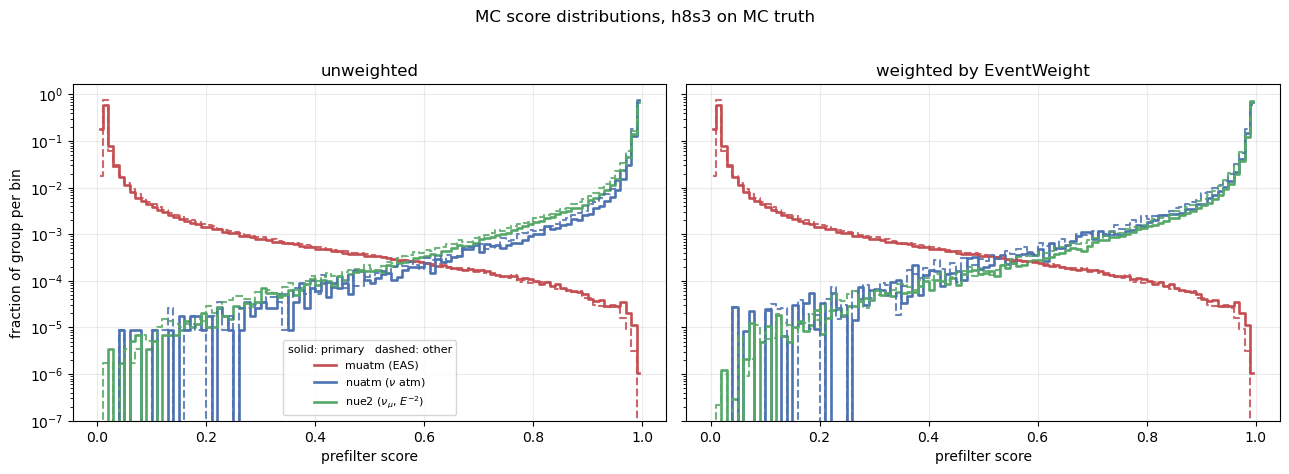

In [5]:
R.plot_score_hists(mc, R.SCORE_EDGES, PRIMARY)

## 2. Neutrino efficiency and EAS suppression

`suppression(t)` is the fraction of muatm passing at threshold `t` — lower is
better; `efficiency(t)` is the fraction of one neutrino class passing. The
threshold grid is the muatm score quantiles at log-spaced pass fractions, so
the curves are resolved deep in the background tail. The dotted vertical line
is the primary model's working point, suppression = $10^{-3}$.

/home/albert/Baikal2025/inference/prefilter/analysis/report_261111_1704/figures/02_efficiency_suppression_roc_da.png


,model,weighted,threshold,suppression,nuatm_2020,nue2_2020
0,"DA, $\lambda$=0.003 (delayed)",False,0.802695,0.001,0.986890,0.978864
1,"control, $\lambda$=0.0",False,0.792045,0.001,0.985784,0.976288
2,"DA, $\lambda$=0.003 (delayed)",True,0.802695,0.001,0.974809,0.981607
3,"control, $\lambda$=0.0",True,0.792045,0.001,0.972123,0.978810


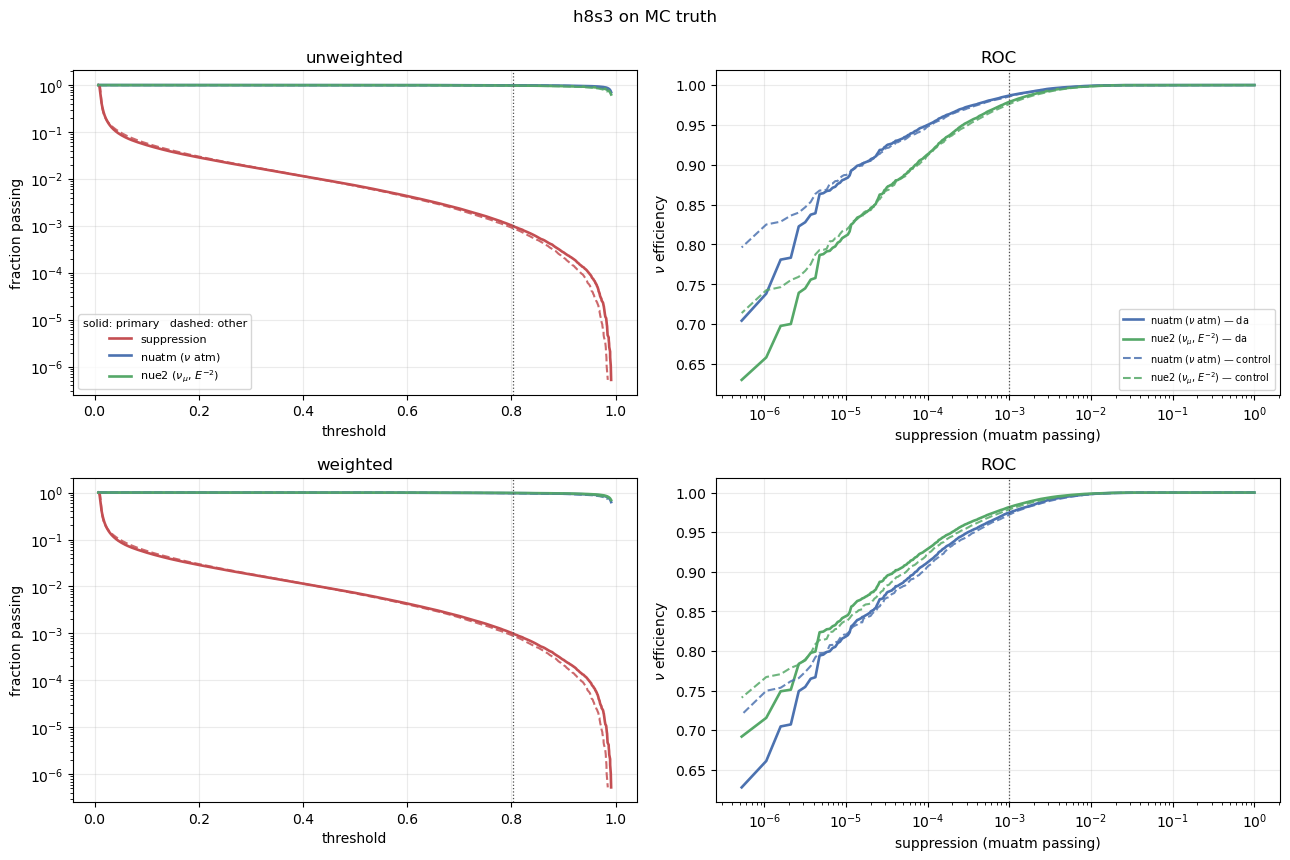

In [6]:
R.plot_threshold_and_roc(mc, PRIMARY)
display(R.working_point_table(mc))

## 3. Efficiency at the working point, suppression = $10^{-3}$

Each model is evaluated at **its own** threshold that puts muatm at a pass
fraction of $10^{-3}$; comparing at one fixed score would confound a shift of
the score scale with a real change in selection power. The MC classes occupy
disjoint zenith hemispheres (muatm 94.2–179.9 deg; neutrinos 0.11–90.00 deg),
which makes this separation easier than a real sample.

/home/albert/Baikal2025/inference/prefilter/analysis/report_261111_1704/figures/03_efficiency_vs_zenith_and_energy_da.png


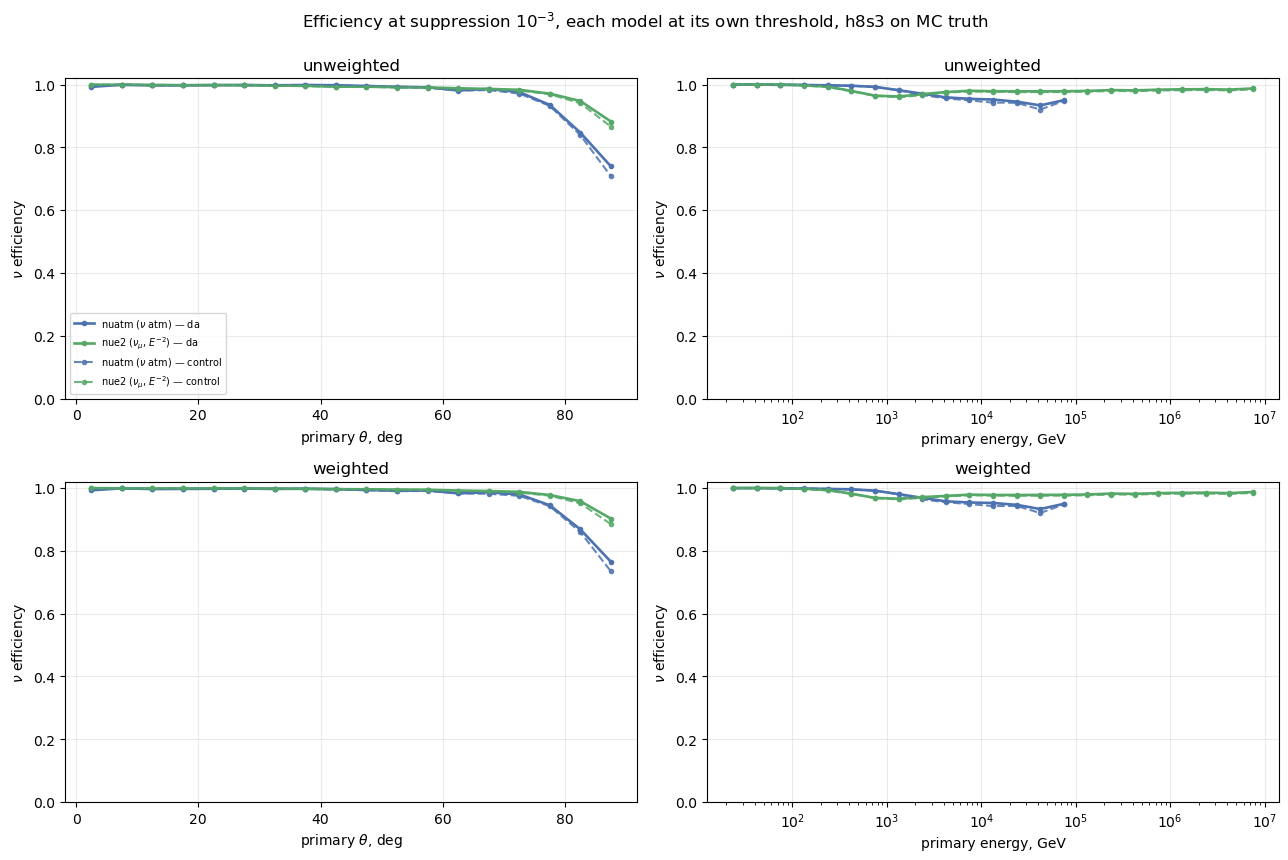

In [7]:
R.plot_efficiency_at_wp(mc, PRIMARY)

## 4. Experimental excess over atmospheric-muon MC

Left: the ratio per score bin. Right: the ratio of the fractions above a
threshold. Both normalise `exp_full` and `muatm` to their own totals. No
live-time normalisation exists for this MC, so the **shape** of the ratio
carries information and its absolute level does not: a value of 3 does not
mean three times too many events, it means the score distribution puts three
times the relative weight there.

/home/albert/Baikal2025/inference/prefilter/analysis/report_261111_1704/figures/04_experimental_excess_da.png


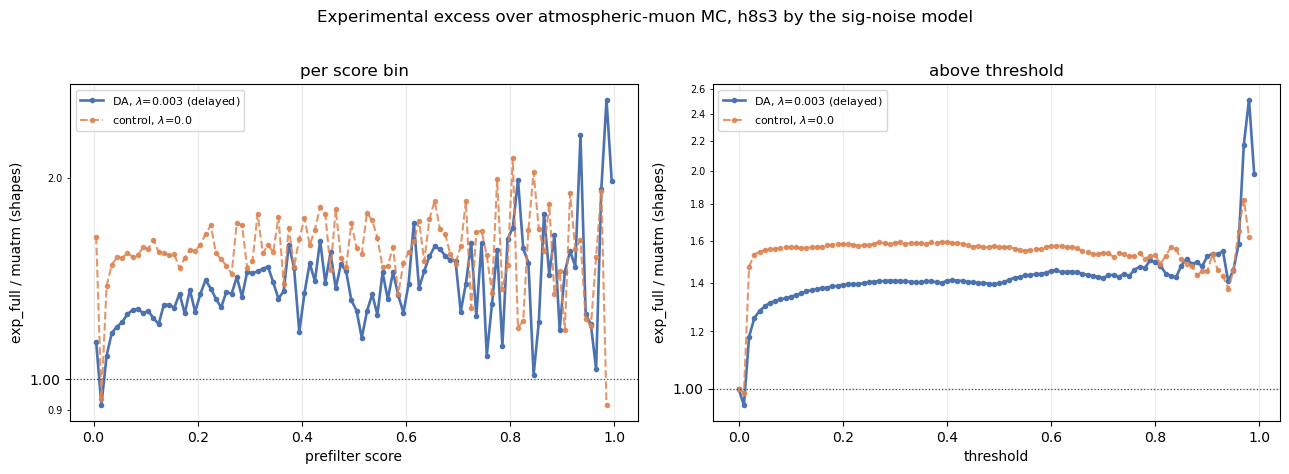

In [8]:
R.plot_exp_excess(exp_counts, muatm_sig, R.SCORE_EDGES, PRIMARY)

## 5. Excess vs muatm fraction

The same experimental/muatm comparison with the threshold replaced by the
**fraction of muatm above it** — the quantity a selection cut actually fixes.
The left panel is the four score survival curves; the right panel is the
`exp_full / muatm` ratio against the muatm fraction, with a 95% Wilson interval
on x and a delta-method ±1σ on y, both axes logarithmic. This mirrors the
nu-classifier's `template_score_survival.ipynb`; the populations are the h8s3
sig-noise counts, the same as figure 4. The dotted vertical line is
suppression = $10^{-3}$. The ratio is a shape ratio: no live-time
normalisation exists, so its absolute level is not a rate.

/home/albert/Baikal2025/inference/prefilter/analysis/report_261111_1704/figures/05_excess_vs_muatm_fraction_da.png


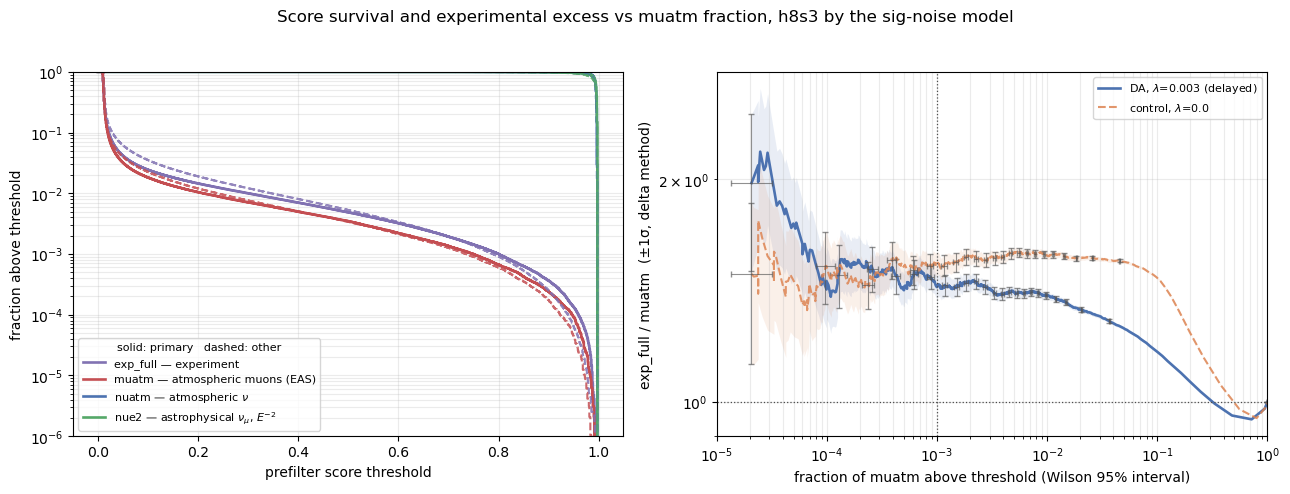

In [9]:
SURVIVAL_EDGES = np.linspace(0.0, 1.0, 1001)
survival_hists = {m: R.survival_histograms(m, SURVIVAL_EDGES)
                  for m in R.MODELS}
R.plot_excess_vs_muatm_fraction(survival_hists, SURVIVAL_EDGES, PRIMARY)

## What this pair does and does not establish

Supported: a shape comparison on MC and on experiment, with the two models
compared at matched working points rather than at a matched score, and the
out-of-training guarantee at the part level.

Not supported:

* absolute event rates — no live-time normalisation for this MC exists here
  (`assumed`);
* a single combined neutrino efficiency — nuatm and nue2 are kept apart on
  purpose;
* a claim that EventWeight is comparable between classes — it is used within a
  class only;
* a per-event out-of-training guarantee finer than the part — the prefilter NPY
  dataset records no `h5_part_keys.npy`;
* full-statistics MC — this prediction set is the reduced 10M/3M/1.29M sample.

Figures are written to `figures/` beside this notebook and are regenerated by
running this notebook end to end. `run_predictions.sh` is the command that
produced the prediction databases they rest on.